# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import joblib
import warnings
warnings.filterwarnings("ignore")



# Load dataset

In [2]:
df=pd.read_csv(r"C:\Users\ADMIN\OneDrive\Desktop\Auspify_ML_Internship\Data\Dataset.csv")
print("Dataset Shape:",df.shape)
df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Missing value:\n",df.isnull().sum())
print("\nUnique value per column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")


Missing value:
 show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Unique value per column:
show_id: 8790
type: 2
title: 8787
director: 4528
country: 86
date_added: 1713
release_year: 74
rating: 14
duration: 220
listed_in: 513


In [4]:
print("Rating count:",df["rating"].value_counts())
print("\nRating percentage:",(df["rating"].value_counts(normalize=True)*100).round(2))

Rating count: rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Rating percentage: rating
TV-MA       36.46
TV-14       24.54
TV-PG        9.80
R            9.09
PG-13        5.57
TV-Y7        3.79
TV-Y         3.48
PG           3.27
TV-G         2.50
NR           0.90
G            0.47
TV-Y7-FV     0.07
NC-17        0.03
UR           0.03
Name: proportion, dtype: float64


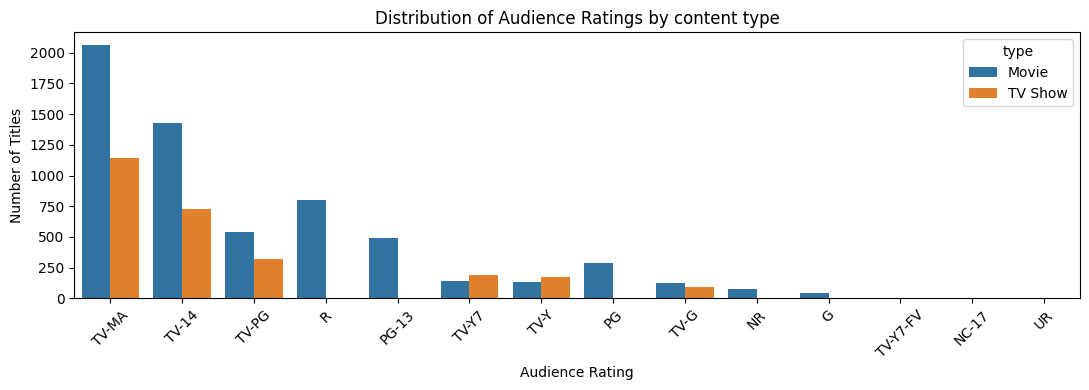

In [5]:
plt.figure(figsize=(11,4))
sns.countplot(
    data=df,
    x="rating",
    order=df["rating"].value_counts().index,hue="type"
)
plt.title("Distribution of Audience Ratings by content type")
plt.xlabel("Audience Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
rating_counts=df["rating"].value_counts()
valid_ratings=rating_counts[rating_counts>=10].index
df_clean=df[df["rating"].isin(valid_ratings)].copy()
print("Original rows:",len(df))
print("Cleaned rows:",len(df_clean))
print("Remaining rating classes:", df_clean["rating"].nunique())

Original rows: 8790
Cleaned rows: 8778
Remaining rating classes: 11


In [7]:
# Extract numeric value from duration (e.g., '90 min' -> 90, '1 Season' -> 1)
df_clean["duration_num"] = df_clean["duration"].str.extract(r"(\d+)").astype(float)

# Keep top 15 countries and group the rest into 'Other' to avoid noisy sparse columns
top_countries = df_clean["country"].value_counts().head(15).index
df_clean["country_clean"] = np.where(
    df_clean["country"].isin(top_countries),
    df_clean["country"],
    "Other"
)

print("Unique countries after grouping:", df_clean["country_clean"].nunique())
df_clean[["type", "country_clean", "release_year", "duration_num", "listed_in"]].head()

Unique countries after grouping: 16


,type,country_clean,release_year,duration_num,listed_in
0,Movie,United States,2020,90.0,Documentaries
1,TV Show,France,2021,1.0,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,United States,2021,1.0,"TV Dramas, TV Horror, TV Mysteries"
3,Movie,Other,2021,91.0,"Children & Family Movies, Comedies"
4,Movie,United States,1993,125.0,"Dramas, Independent Movies, International Movies"


In [8]:
X = df_clean[["type", "country_clean", "release_year", "duration_num", "listed_in"]]
y = df_clean["rating"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nTraining target classes:", y_train.nunique())
print("Testing target classes:", y_test.nunique())

X_train shape: (7022, 5)
X_test shape: (1756, 5)

Training target classes: 11
Testing target classes: 11


In [9]:
# Parse comma-separated genres
train_genres = [[g.strip() for g in item.split(",")] for item in X_train["listed_in"]]
test_genres = [[g.strip() for g in item.split(",")] for item in X_test["listed_in"]]

mlb = MultiLabelBinarizer()
genre_train_encoded = mlb.fit_transform(train_genres)
genre_test_encoded = mlb.transform(test_genres)

genre_train_df = pd.DataFrame(genre_train_encoded, columns=mlb.classes_, index=X_train.index)
genre_test_df = pd.DataFrame(genre_test_encoded, columns=mlb.classes_, index=X_test.index)

print("Genre train shape:", genre_train_df.shape)
print("Genre test shape:", genre_test_df.shape)

Genre train shape: (7022, 42)
Genre test shape: (1756, 42)


In [10]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

cat_train_encoded = encoder.fit_transform(X_train[["type", "country_clean"]])
cat_test_encoded = encoder.transform(X_test[["type", "country_clean"]])

cat_cols = encoder.get_feature_names_out(["type", "country_clean"])

cat_train_df = pd.DataFrame(cat_train_encoded, columns=cat_cols, index=X_train.index)
cat_test_df = pd.DataFrame(cat_test_encoded, columns=cat_cols, index=X_test.index)

print("Categorical train shape:", cat_train_df.shape)
print("Categorical test shape:", cat_test_df.shape)

Categorical train shape: (7022, 18)
Categorical test shape: (1756, 18)


In [11]:
num_train_df = X_train[["release_year", "duration_num"]].copy()
num_test_df = X_test[["release_year", "duration_num"]].copy()

X_train_final = pd.concat([num_train_df, cat_train_df, genre_train_df], axis=1)
X_test_final = pd.concat([num_test_df, cat_test_df, genre_test_df], axis=1)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)
print("Columns identical:", X_train_final.columns.equals(X_test_final.columns))
print("Missing values:", X_train_final.isnull().sum().sum() + X_test_final.isnull().sum().sum())

Final training shape: (7022, 62)
Final testing shape: (1756, 62)
Columns identical: True
Missing values: 0


In [12]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_final, y_train)
y_pred_lr = lr_model.predict(X_test_final)

print("Logistic Regression Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.4356

Classification Report:
               precision    recall  f1-score   support

           G       0.00      0.00      0.00         8
          NR       0.00      0.00      0.00        16
          PG       1.00      0.04      0.07        57
       PG-13       0.00      0.00      0.00        98
           R       0.35      0.53      0.42       160
       TV-14       0.47      0.37      0.41       432
        TV-G       0.00      0.00      0.00        44
       TV-MA       0.45      0.79      0.58       641
       TV-PG       0.18      0.03      0.06       172
        TV-Y       0.32      0.16      0.22        61
       TV-Y7       0.00      0.00      0.00        67

    accuracy                           0.44      1756
   macro avg       0.25      0.17      0.16      1756
weighted avg       0.37      0.44      0.37      1756



In [13]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_final, y_train)
y_pred_dt = dt_model.predict(X_test_final)

print("Decision Tree Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.4567

Classification Report:
               precision    recall  f1-score   support

           G       0.42      0.62      0.50         8
          NR       0.00      0.00      0.00        16
          PG       0.50      0.44      0.47        57
       PG-13       0.36      0.38      0.37        98
           R       0.46      0.46      0.46       160
       TV-14       0.42      0.41      0.42       432
        TV-G       0.17      0.18      0.18        44
       TV-MA       0.57      0.59      0.58       641
       TV-PG       0.22      0.21      0.21       172
        TV-Y       0.50      0.46      0.48        61
       TV-Y7       0.48      0.54      0.51        67

    accuracy                           0.46      1756
   macro avg       0.37      0.39      0.38      1756
weighted avg       0.45      0.46      0.45      1756



In [14]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_final, y_train)
y_pred_rf = rf_model.predict(X_test_final)

print("Random Forest Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.5177

Classification Report:
               precision    recall  f1-score   support

           G       0.62      0.62      0.62         8
          NR       0.00      0.00      0.00        16
          PG       0.62      0.53      0.57        57
       PG-13       0.48      0.41      0.44        98
           R       0.51      0.53      0.52       160
       TV-14       0.48      0.44      0.46       432
        TV-G       0.15      0.09      0.11        44
       TV-MA       0.60      0.69      0.64       641
       TV-PG       0.25      0.23      0.24       172
        TV-Y       0.56      0.61      0.58        61
       TV-Y7       0.56      0.55      0.56        67

    accuracy                           0.52      1756
   macro avg       0.44      0.43      0.43      1756
weighted avg       0.50      0.52      0.51      1756



In [15]:
baseline_preds = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest (Default)": y_pred_rf
}

comparison_rows = []
for name, preds in baseline_preds.items():
    rep = classification_report(y_test, preds, output_dict=True)
    comparison_rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Macro F1": round(rep["macro avg"]["f1-score"], 4),
        "Weighted F1": round(rep["weighted avg"]["f1-score"], 4)
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(by="Weighted F1", ascending=False)
print(comparison_df.to_string(index=False))

                  Model  Accuracy  Macro F1  Weighted F1
Random Forest (Default)    0.5177    0.4314       0.5080
          Decision Tree    0.4567    0.3788       0.4546
    Logistic Regression    0.4356    0.1593       0.3651


In [16]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=12,
    cv=cv,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_final, y_train)
final_model = random_search.best_estimator_

print("Best Parameters:", random_search.best_params_)
print("Best 5-Fold CV Weighted F1:", round(random_search.best_score_, 4))

Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': None}
Best 5-Fold CV Weighted F1: 0.5422


Tuned Random Forest Test Accuracy: 0.5518

Final Classification Report:

              precision    recall  f1-score   support

           G       1.00      0.38      0.55         8
          NR       0.00      0.00      0.00        16
          PG       0.61      0.53      0.57        57
       PG-13       0.54      0.39      0.45        98
           R       0.53      0.56      0.54       160
       TV-14       0.54      0.45      0.49       432
        TV-G       0.00      0.00      0.00        44
       TV-MA       0.59      0.81      0.68       641
       TV-PG       0.30      0.13      0.18       172
        TV-Y       0.49      0.62      0.55        61
       TV-Y7       0.51      0.54      0.52        67

    accuracy                           0.55      1756
   macro avg       0.46      0.40      0.41      1756
weighted avg       0.52      0.55      0.52      1756



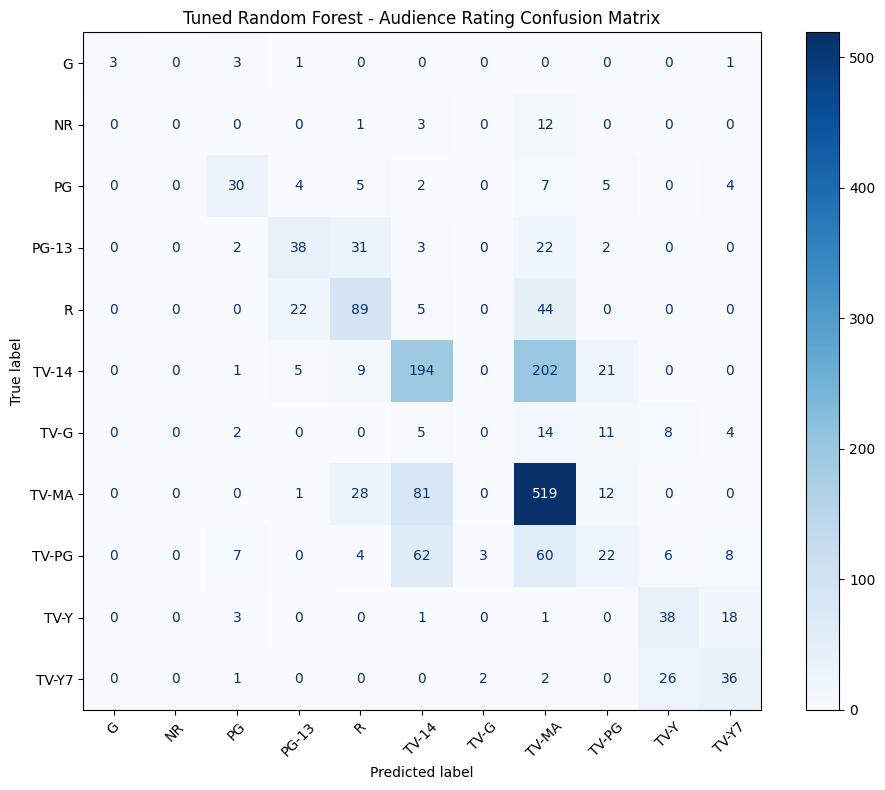

In [17]:
y_pred_final = final_model.predict(X_test_final)

print("Tuned Random Forest Test Accuracy:", round(accuracy_score(y_test, y_pred_final), 4))
print("\nFinal Classification Report:\n")
print(classification_report(y_test, y_pred_final))

# Plot 11x11 Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_final,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)
plt.title("Tuned Random Forest - Audience Rating Confusion Matrix")
plt.tight_layout()
plt.show()

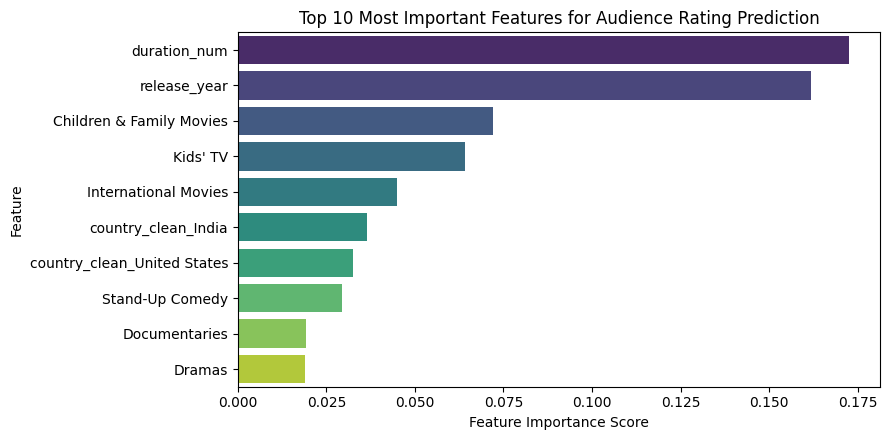

In [18]:
importances = pd.Series(
    final_model.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Top 10 Most Important Features for Audience Rating Prediction")
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [19]:
inference_artifacts = {
    "model": final_model,
    "encoder": encoder,
    "mlb": mlb,
    "top_countries": list(top_countries),
    "feature_columns": X_train_final.columns.tolist()
}

joblib.dump(inference_artifacts, "rating_inference_artifacts.pkl")
print("Saved rating_inference_artifacts.pkl successfully!")

Saved rating_inference_artifacts.pkl successfully!


In [20]:
loaded_artifacts = joblib.load("rating_inference_artifacts.pkl")

def predict_rating(sample_df, artifacts):
    df_in = sample_df.copy()
    df_in["duration_num"] = df_in["duration"].str.extract(r"(\d+)").astype(float)
    df_in["country_clean"] = np.where(
        df_in["country"].isin(artifacts["top_countries"]),
        df_in["country"],
        "Other"
    )

    cat_enc = artifacts["encoder"].transform(df_in[["type", "country_clean"]])
    cat_df = pd.DataFrame(
        cat_enc,
        columns=artifacts["encoder"].get_feature_names_out(["type", "country_clean"]),
        index=df_in.index
    )

    genres_parsed = [[g.strip() for g in item.split(",")] for item in df_in["listed_in"]]
    genre_enc = artifacts["mlb"].transform(genres_parsed)
    genre_df = pd.DataFrame(genre_enc, columns=artifacts["mlb"].classes_, index=df_in.index)

    processed = pd.concat([df_in[["release_year", "duration_num"]], cat_df, genre_df], axis=1)
    processed = processed.reindex(columns=artifacts["feature_columns"], fill_value=0)

    return artifacts["model"].predict(processed)

# Pull first 5 raw test records directly from df_clean
sample_raw = df_clean.loc[
    X_test.index[:5],
    ["type", "country", "release_year", "duration", "listed_in"]
].copy()

preds_check = predict_rating(sample_raw, loaded_artifacts)
check_df = pd.DataFrame({
    "Actual": y_test.loc[sample_raw.index].values,
    "Predicted": preds_check,
    "Match": y_test.loc[sample_raw.index].values == preds_check
})

print(check_df)

  Actual Predicted  Match
0  TV-14     TV-14   True
1  TV-14     TV-MA  False
2  TV-14     TV-14   True
3  TV-MA     TV-MA   True
4  TV-MA     TV-MA   True
